# Kaj se je zgodilo z IT in odpuščanji po koronavirusu?
### Zgodba v grafih

To je zgodba o tem, kaj se dogaja v tehnološkem svetu od leta 2020: **kdaj** so podjetja napovedovala odpuščanja, **zakaj** morda ravno takrat, **katera podjetja** so bila najbolj na udaru, **kaj iščejo delodajalci**, **kje** v ZDA se je delo spremenilo in **kako se je odzvala borza**.

Vsi grafi so interaktivni: miško premakni na točko ali črto in vidiš točne vrednosti; z vlečenjem približaš del grafa, z dvoklikom se vrneš nazaj.

**Kako brati to zgodbo.** Pod vsakim grafom so štirje kratki odgovori:

- **Kaj vidimo?** Kako se graf bere.
- **Zakaj smo to naredili?** Katero vprašanje nas je zanimalo.
- **Kaj to pomeni?** Kaj kažejo podatki, s številkami, izračunanimi iz podatkov.
- **Česa ne vemo?** Kaj podatki ne morejo pokazati. To je pomemben del: večinoma vidimo, kaj se je dogajalo *ob istem času*, ne pa *zakaj*.

**Odkod podatki.** Seznam napovedanih odpuščanj (Layoffs.fyi), javni računovodski podatki podjetij (ameriška komisija SEC), obrestne mere in borzni indeks (FRED), uradna statistika trga dela (BLS), mesečne objave "Who is hiring?" na Hacker Newsu in cene delnic (Yahoo Finance).

In [1]:
from pathlib import Path
import os, sys
from IPython.display import Markdown, display

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "build_master.py").exists())
sys.path.insert(0, str(ROOT)); os.chdir(ROOT)          # poti do podatkov so relativne glede na mapo projekta
import plotly.io as pio
from analysis import viz, story_text as tx
from analysis.viz_theme import explanation_markdown

# Grafi se vidijo v JupyterLab in v izvoženem HTML (ta potrebuje internet, da naloži plotly.js).
# Za izvoz, ki dela brez interneta, zamenjaj z "notebook" (datoteka je večja za okoli 4 MB).
pio.renderers.default = "plotly_mimetype+notebook_connected"

story = viz.prepare_story_data()                       # zažene obstoječe analize (nekaj minut)
figs = viz.build_figures(story)
explain = tx.build_explanations(story)

try:                                                   # poglavji 4 in 5 (Hacker News in zemljevid) pripravi drugi del ekipe
    from analysis import viz_text_geo as vtg
    for name, (fig, parts) in vtg.build_chapter_4_5().items():
        figs[name], explain[name] = fig, parts
    story["hn"] = {"flags": vtg.load_flags(), "change_points": vtg.load_change_points()}
    story["geo"] = vtg.load_map_data()
except Exception:
    pass


def show(name):
    """Graf in pod njim štiri razlage v preprostem jeziku."""
    figs[name].show()
    display(Markdown(explanation_markdown(explain[name])))


def show_chapter(order, prefix, missing_text):
    names = [n for n in order if n in figs] + sorted(k for k in figs if k.startswith(prefix) and k not in order)
    if not names:
        display(Markdown(missing_text))
    for n in names:
        show(n)

## 1. Kdaj so podjetja napovedovala odpuščanja?

Začnimo s preprostim vprašanjem: kdaj? Prvi graf postavi na isto os več stvari, ki jih običajno gledamo ločeno. Drugi pokaže, kako se napovedi razporejajo po tednih v letu.

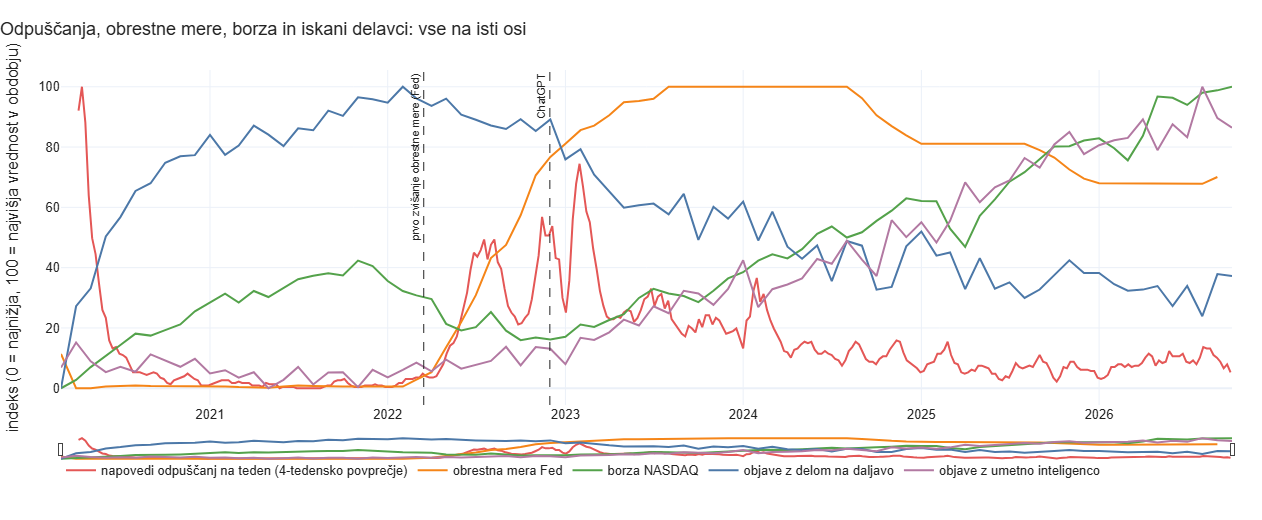

**Kaj vidimo?** Na enem grafu je več črt: koliko odpuščanj so podjetja napovedala na teden, obrestna mera ameriške centralne banke (Fed), borzni indeks NASDAQ in, če so podatki na voljo, delež objav za delo na Hacker Newsu, ki omenjajo delo na daljavo oziroma umetno inteligenco. Vsako črto smo preračunali na lestvico od 0 do 100, da jih lahko primerjamo; ko miško premakneš na črto, vidiš pravo vrednost. Črtkani črti označujeta prvo zvišanje obrestne mere in izid ChatGPT.

**Zakaj smo to naredili?** Hoteli smo videti, ali se te stvari dogajajo ob istem času. Številke imajo različne enote (število, odstotki, točke), zato jih brez preračuna ne bi mogli narisati na isto os.

**Kaj to pomeni?** V 26 tednih pred prvim zvišanjem obrestne mere (16. 3. 2022) je bilo povprečno 1,0 napovedi na teden, v 26 tednih po njem 15,4; obrestna mera je zrasla z 0,1 % na 5,3 %; borzni indeks NASDAQ je od vrha do dna izgubil 32 %. Dražji denar, padec borze in val napovedanih odpuščanj so se torej zgodili v istem obdobju.

**Česa ne vemo?** Dogajanje ob istem času še ne dokazuje vzroka. Seznam odpuščanj beleži napovedi, ne števila dejansko odpuščenih ljudi, in je po letu 2022 postal bolj znan, zato se je lahko povečalo tudi samo beleženje.

In [2]:
show("1_casovnica")

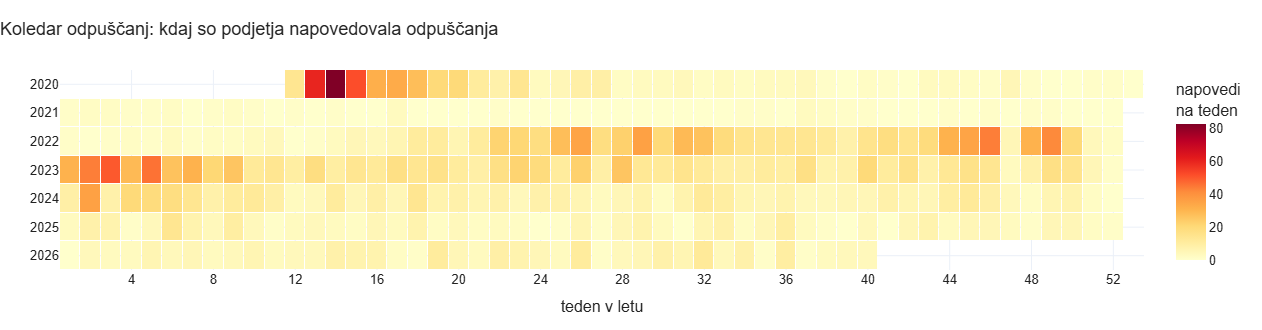

**Kaj vidimo?** Vsaka vrstica je eno leto, vsak stolpec en teden v letu. Čim temnejše je polje, tem več odpuščanj so podjetja v tistem tednu napovedala. Prazna polja pomenijo, da za tisti teden nimamo podatkov. Ko miško premakneš na polje, vidiš točno število.

**Zakaj smo to naredili?** Hoteli smo videti, ali so napovedi razporejene enakomerno ali pridejo v valovih.

**Kaj to pomeni?** Največ napovedi je bilo leta 2023 (859). Najbolj pretresljiv je bil teden z začetkom 30. 3. 2020, ko je bilo napovedanih 83 odpuščanj. Polovica vseh napovedi je padla v samo 51 od 342 tednov, torej v zelo kratkih valovih.

**Česa ne vemo?** Seznam odpuščanj se je začel marca 2020, zato so prvi tedni prazni. Pozna se tudi to, da se beležijo predvsem znana podjetja.

In [3]:
show("1_koledar")

## 2. Zakaj ravno takrat?

Zdaj vprašanje "zakaj". Preverimo tri pogoste razlage: dražji denar in padec borze, dva znana datuma (prvo zvišanje obrestne mere in izid ChatGPT) ter prezaposlovanje v času razcveta. Pri vsaki povemo, kaj smo preizkusili in česa podatki ne morejo pokazati.

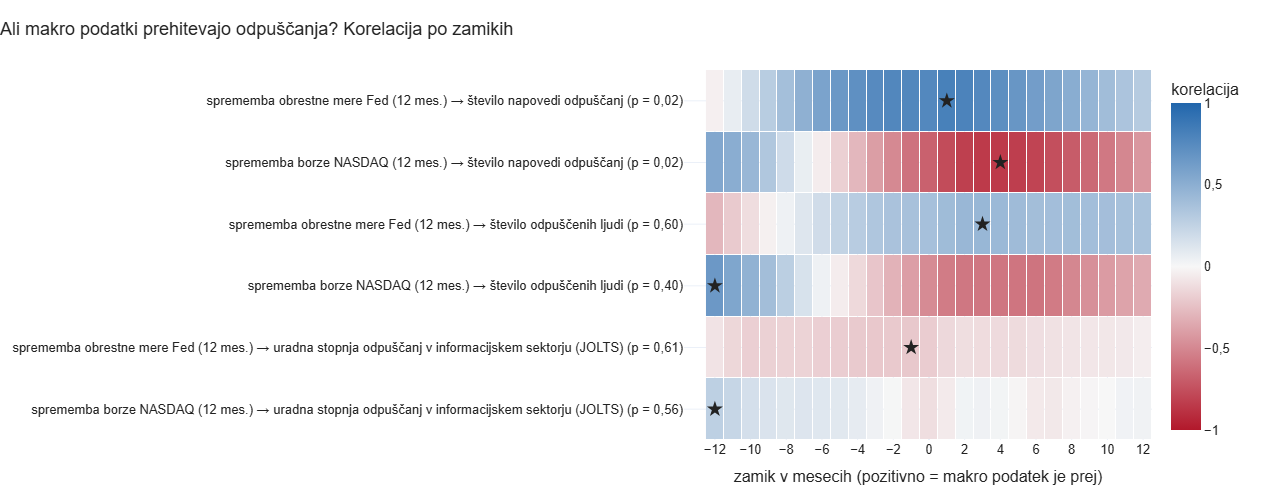

**Kaj vidimo?** Vsaka vrstica primerja eno makro številko (kako se je v zadnjih 12 mesecih spremenila obrestna mera ali borza) z enim merilom odpuščanj. Stolpci so zamiki v mesecih: kaj dobimo, če odpuščanja primerjamo z makro podatkom izpred nekaj mesecev (pozitiven zamik) ali nekaj mesecev pozneje (negativen). Modra pomeni, da se vrsti premikata v isto smer, rdeča v nasprotno; zvezdica označuje najmočnejši zamik.

**Zakaj smo to naredili?** Vprašali smo se, ali dražji denar in padec borze 'prehitevata' odpuščanja, in ali to velja za vsa merila: število napovedi, število odpuščenih ljudi in uradno statistiko.

**Kaj to pomeni?** Število napovedi se ujema s spremembo obrestne mere: korelacija 0,82, p = 0,02, kar pomeni, da bi tako dobro ujemanje videli le v približno 2 % naključnih premikov vrste po koledarju. Število napovedi se ujema s spremembo borze: korelacija -0,85, p = 0,02, kar pomeni, da bi tako dobro ujemanje videli le v približno 2 % naključnih premikov vrste po koledarju. Pri številu odpuščenih ljudi in pri uradni statistiki (JOLTS) povezave ni videti (p od 0,40 do 0,61). Z besedami: število napovedanih odpuščanj sledi obrestnim meram in borzi, a to ne pomeni nujno, da je odpuščenih več ljudi.

**Česa ne vemo?** Imamo en cikel obrestnih mer in okoli šest let podatkov, zato se skoraj vsaki dve vrsti, ki v tem času rasteta ali padata, ujemata; test to upošteva le delno. 12-mesečna sprememba zaostaja za pravo spremembo, zato zamik +1 ne pomeni, da je obrestna mera delovala mesec prej. Vzroka s tem ne dokažemo.

In [4]:
show("2_zamiki")

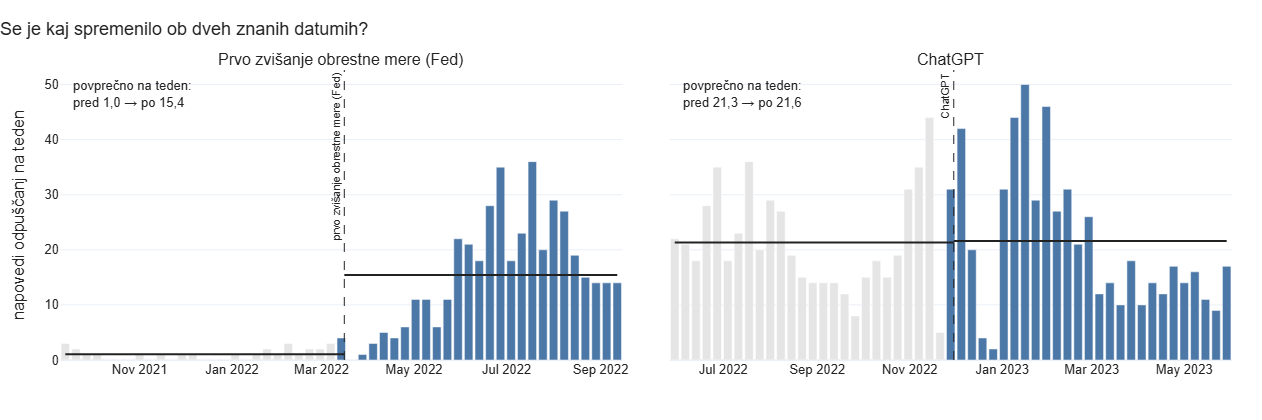

**Kaj vidimo?** Dva grafa: levi kaže tedne okoli prvega zvišanja obrestne mere Fed (16. 3. 2022), desni okoli izida ChatGPT (30. 11. 2022). Vsak stolpec je en teden, 26 tednov pred in 26 tednov po datumu. Siva polja so pred datumom, modra po njem, vodoravni črti pa kažeta povprečje pred in po.

**Zakaj smo to naredili?** Pogosto slišimo, da sta ta dva trenutka prelomnici za odpuščanja. Preverili smo, ali se je število napovedi res spremenilo prav takrat.

**Kaj to pomeni?** Okoli zvišanja obrestne mere je bilo povprečje 1,0 napovedi na teden pred datumom in 15,4 po njem. Okoli izida ChatGPT 21,3 pred in 21,6 po datumu, torej skoraj nespremenjeno. Če za vsak teden v celotnem obdobju izračunamo enako primerjavo, je največji skok v tednu z začetkom 23. 5. 2022, približno 10 tednov po prvem zvišanju obrestne mere.

**Česa ne vemo?** Datuma sta le osem mesecev narazen in v istem obdobju padanja borze, zato ju podatki ne morejo ločiti. Poleg tega seznam odpuščanj ne pove, ali je bil razlog umetna inteligenca, zato lahko le rečemo, kdaj se je število napovedi spremenilo, ne zakaj.

In [5]:
show("2_datumi")

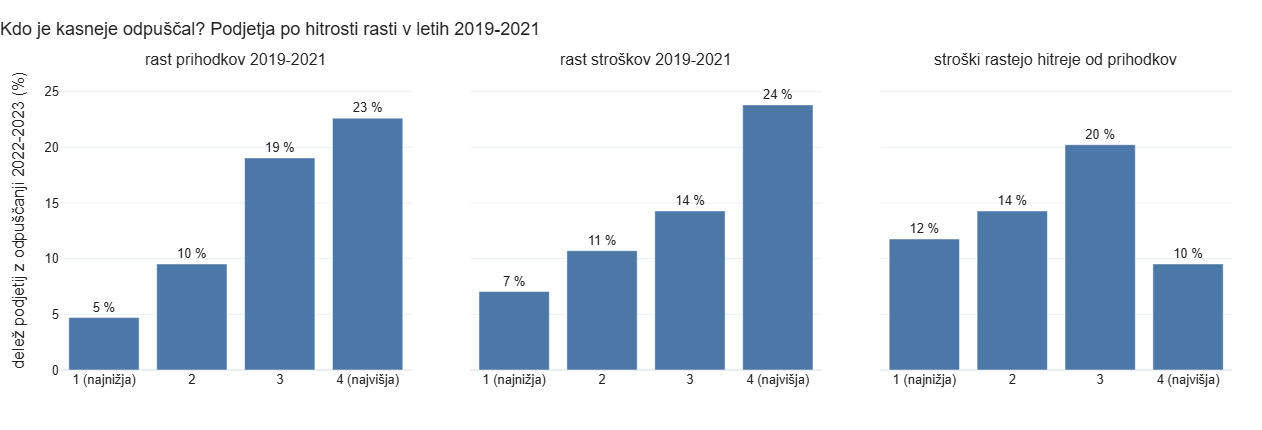

**Kaj vidimo?** Podjetja smo razvrstili v štiri enako velike skupine glede na to, kako hitro so rasla v letih 2019 do 2021: po rasti prihodkov, po rasti stroškov in po tem, ali so stroški rasli hitreje od prihodkov. Stolpec kaže, kolikšen delež podjetij iz skupine je v letih 2022 in 2023 napovedal odpuščanja.

**Zakaj smo to naredili?** Preverjamo pogosto razlago, da so podjetja v času razcveta zaposlovala preveč in morala zato kasneje odpuščati.

**Kaj to pomeni?** Med podjetji z najpočasnejšo rastjo prihodkov je odpuščanja napovedalo 5 %, med najhitreje rastočimi 23 %; delež narašča iz skupine v skupino. Če podjetja razvrstimo po tem, ali so stroški rasli hitreje od prihodkov, so deleži od 10 % do 20 % in ne naraščajo enakomerno. Hitra rast torej gre z odpuščanji, kar pa še ne pomeni, da so podjetja zaposlovala preveč glede na prihodke.

**Česa ne vemo?** Nimamo števila zaposlenih, zato stroški le približno nadomeščajo zaposlovanje (vključujejo tudi nakupe podjetij in plačevanje z delnicami). Hitro rastoča podjetja so pogosto bolj znana, zato jih seznam odpuščanj lažje zazna. V vsaki skupini je le nekaj deset podjetij, zato so razlike negotove.

In [6]:
show("2_rast")

## 3. Katera podjetja se znajdejo na seznamu?

Naslednje vprašanje: ali lahko po javnih računovodskih podatkih podjetja vnaprej ocenimo, katera bodo napovedala odpuščanja, in kaj to ocenjevanje poganja?

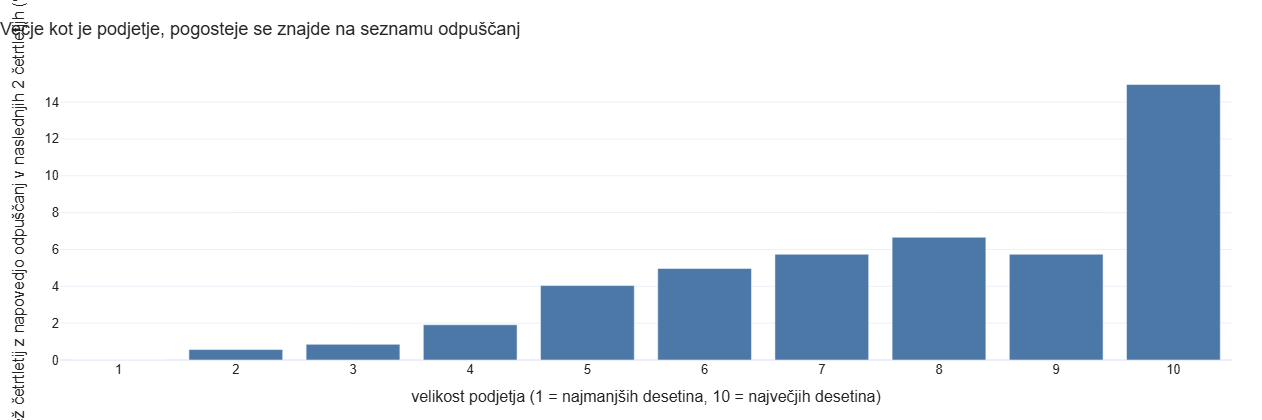

**Kaj vidimo?** Podjetja smo po vrednosti njihovih sredstev razdelili v deset enako velikih skupin: od najmanjših (1) do največjih (10). Stolpec kaže, v kolikšnem deležu četrtletij je podjetju v naslednjih dveh četrtletjih sledila napoved odpuščanj. Ko miško premakneš na stolpec, vidiš število četrtletij.

**Zakaj smo to naredili?** Hoteli smo ugotoviti, kaj najbolj loči podjetja, ki se znajdejo na seznamu odpuščanj, od tistih, ki se ne.

**Kaj to pomeni?** Pri najmanjših podjetjih je napovedi sledilo 0,0 % četrtletij, pri največjih 15,0 %, torej veliko pogosteje. Velikost podjetja je v naših podatkih zelo močno sporočilo.

**Česa ne vemo?** Veliko podjetje je tudi bolj opazno: seznam odpuščanj beleži predvsem znana podjetja. Velikost zato verjetno meri tudi to, kako zanesljivo je podjetje sploh zabeleženo, ne le, kako veliko je tveganje za odpuščanja.

In [7]:
show("3_velikost")

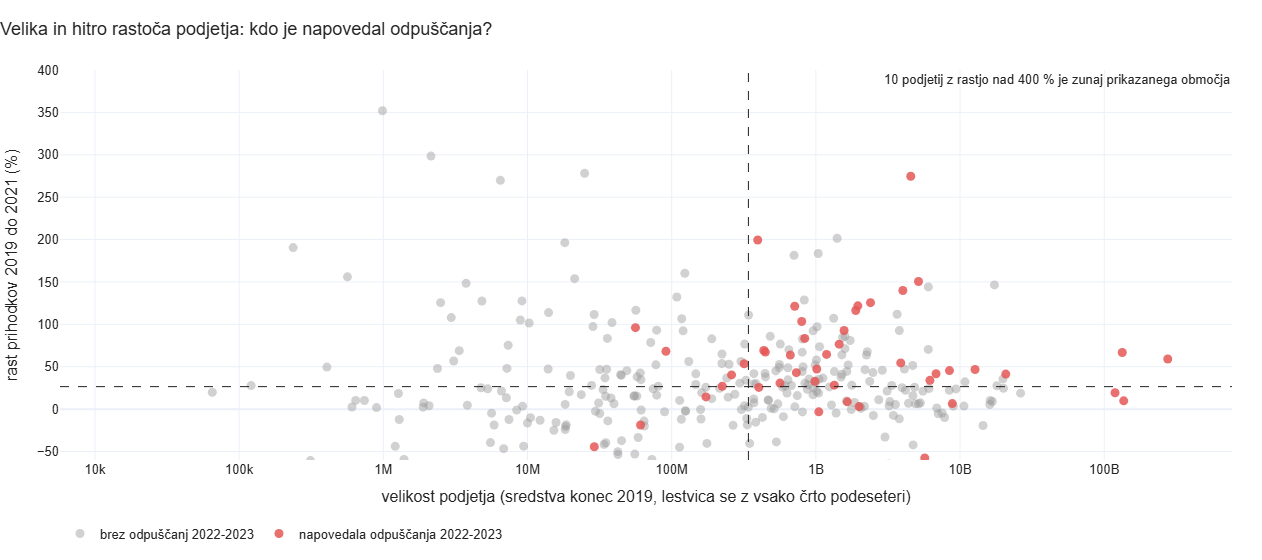

**Kaj vidimo?** Vsaka pika je eno podjetje. Vodoravno je velikost (sredstva ob koncu 2019; lestvica se z vsako črto podeseteri), navpično rast prihodkov med letoma 2019 in 2021. Rdeče pike so podjetja, ki so v letih 2022 in 2023 napovedala odpuščanja, sive tista, ki niso. Črtkani črti sta mediani: pol podjetij je levo od navpične črte, pol desno, in enako za vodoravno. Ko miško premakneš na piko, vidiš ime podjetja.

**Zakaj smo to naredili?** Hoteli smo videti obe razlagi hkrati: ali odpuščajo predvsem velika podjetja, hitro rastoča podjetja ali oboja.

**Kaj to pomeni?** Med 94 podjetji, ki so nad mediano tako po velikosti kot po rasti (zgornji desni kot), je odpuščanja napovedalo 32 %, med ostalimi 242 pa 7 %, torej približno 4,8-krat pogosteje.

**Česa ne vemo?** Vsaka pika je le eno podjetje, zato so izjeme. Sredstva so le približek velikosti, rast prihodkov pa ne pove, koliko ljudi so podjetja zaposlila. Seznam odpuščanj beleži predvsem znana podjetja, zato so velika podjetja že vnaprej bolj vidna.

In [8]:
show("3_podjetja")

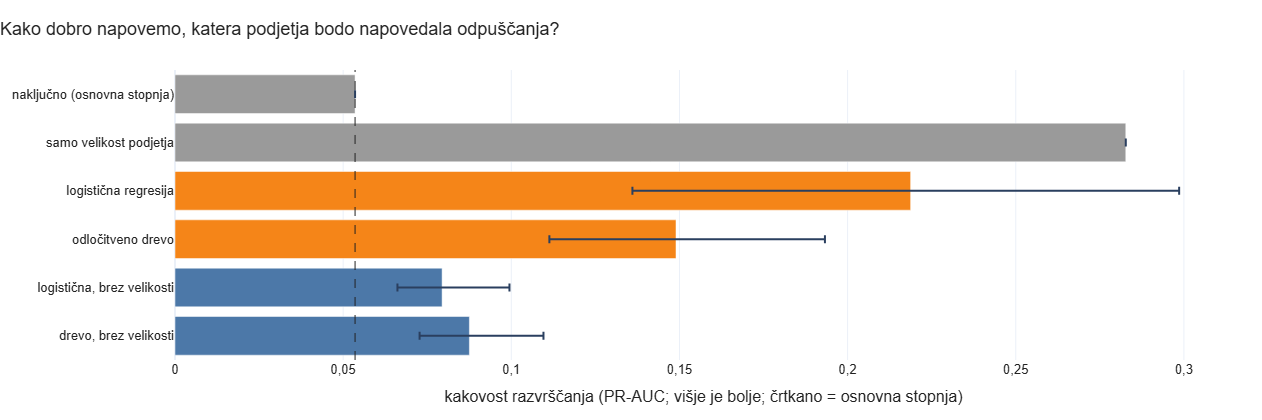

**Kaj vidimo?** Primerjamo, kako dobro različni modeli razvrstijo podjetja od tistih, ki bodo po vsej verjetnosti napovedala odpuščanja, do tistih, ki jih ne bodo. Mera se imenuje PR-AUC: višja vrednost pomeni, da so podjetja, ki so res napovedala odpuščanja, višje na seznamu. Črtkana črta je rezultat naključnega ugibanja. Črte na stolpcih kažejo negotovost (z 95-odstotno zanesljivostjo je prava vrednost nekje v tem območju).

**Zakaj smo to naredili?** Zanimalo nas je, ali lahko iz javnih računovodskih podatkov podjetij vnaprej ocenimo, kdo bo napovedal odpuščanja, in še bolj, od česa je ta uspeh odvisen.

**Kaj to pomeni?** Logistični model doseže 0,22, kar je 4,1-krat boljše od naključja (0,05). Samo velikost podjetja doseže 0,28. Ko modelu velikost vzamemo, pade na 0,08 (1,5-krat boljše od naključja). Skoraj vse, kar modeli znajo, torej pride iz velikosti podjetja.

**Česa ne vemo?** Preizkušali smo na 386 napovedih odpuščanj, ki jih je dalo 131 podjetij v letih od 2023 naprej; učili smo se na starejših podatkih, ki jih je bilo bistveno manj. Model zna razvrščati, ne zna pa zanesljivo povedati, kako verjetno je odpuščanje (verjetnosti so v povprečju prenizke). Ne pove nam tudi, zakaj podjetja odpuščajo.

In [9]:
show("3_modeli")

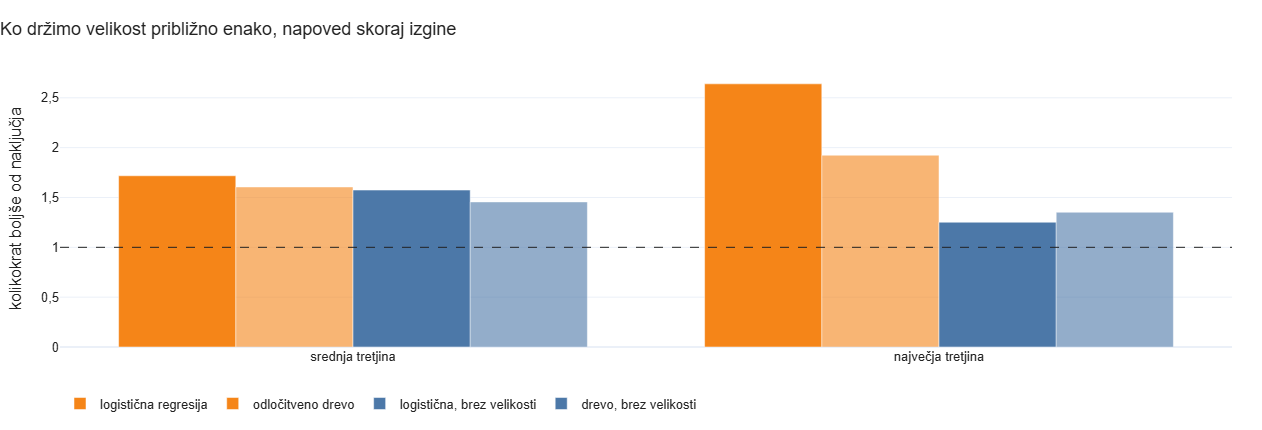

**Kaj vidimo?** Podjetja smo razdelili v tretjine po velikosti. V vsaki tretjini vidimo, kolikokrat je model boljši od naključnega ugibanja (1 pomeni: nič boljši). Oranžni stolpci so modeli, ki poznajo velikost, modri tisti, ki je ne. Tretjine z občutno premalo napovedmi odpuščanj ne ocenjujemo.

**Zakaj smo to naredili?** Če velikost približno držimo na isti ravni, vidimo, ali ostane še kaj, iz česar bi lahko ocenili tveganje.

**Kaj to pomeni?** Med največjimi podjetji je model z velikostjo 2,6-krat boljši od naključja, brez velikosti pa 1,3-krat. Med srednje velikimi podjetji je model 1,7-krat boljši od naključja.

**Česa ne vemo?** V najmanjši tretjini je le 14 napovedi odpuščanj med 2.486 četrtletji, zato je izpustimo. Tudi znotraj tretjine so podjetja različno velika, zato velikost ni popolnoma izenačena. Število podjetij s pozitivnim izidom je omejeno, zato so razlike med modeli negotove.

In [10]:
show("3_skupine")

## 4. Kaj iščejo delodajalci?

Pogled z druge strani: ne kdo odpušča, ampak kaj delodajalci iščejo. Uporabili smo mesečne objave "Who is hiring?" na Hacker Newsu, kjer podjetja objavljajo prosta delovna mesta. To je zanimiv, a poseben vzorec: gre predvsem za startupe in tehnološka podjetja, zato ne govori za vse delodajalce.

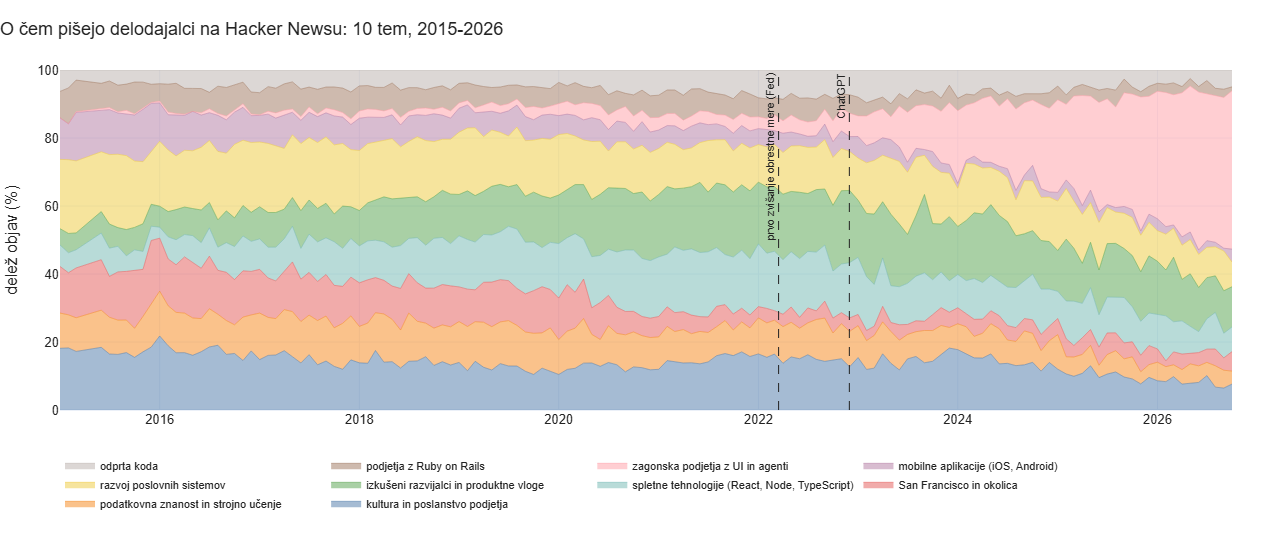

**Kaj vidimo?** Vsaka barvna plast je ena tema, ki jo je računalnik sam našel v besedilih oglasov za delo. Debelina plasti pove, kolikšen delež objav v tistem mesecu govori predvsem o tej temi; skupaj plasti vedno dajo 100 %. Ko miško premakneš na plast, vidiš ime teme in njen delež; črtkani črti označujeta prvo zvišanje obrestne mere in ChatGPT.

**Zakaj smo to naredili?** Hoteli smo videti, ali se je spremenilo, o čem delodajalci pišejo, ko iščejo ljudi: o tehnologijah, o vrsti dela ali o podjetju.

**Kaj to pomeni?** V prvih 12 mesecih s podatki (1/2015 do 2/2016) je bila najpogostejša tema »razvoj poslovnih sistemov« (20 % objav), v zadnjih 12 mesecih pa »zagonska podjetja z UI in agenti« (42 %). Najbolj je narasla tema »zagonska podjetja z UI in agenti« (z 0 % na 42 %), najbolj je padla »mobilne aplikacije (iOS, Android)« (z 13 % na 2 %).

**Česa ne vemo?** Hacker News je kotiček trga, kjer prevladujejo zagonska podjetja (startupi) iz ZDA, zato ne predstavlja vseh delodajalcev. Teme je določil algoritem (vsaka objava je pripisana svoji najmočnejši temi), imena tem pa smo dali mi; z drugim številom tem bi bila razdelitev nekoliko drugačna. Graf kaže, o čem se piše, ne koliko ljudi je zaposlenih.

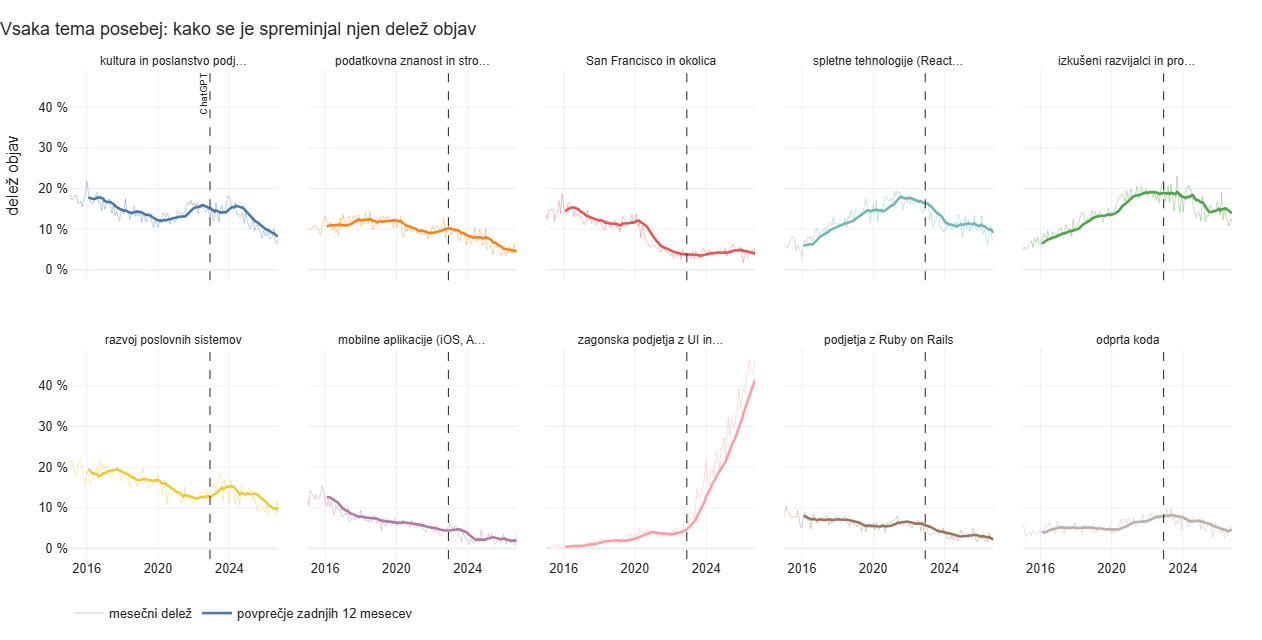

**Kaj vidimo?** Vsak mali graf je ena od 10 tem. Tanka črta je delež objav v posameznem mesecu, debela pa povprečje zadnjih 12 mesecev, ki skrije mesečno nihanje. Vsi grafi imajo enako navpično os, zato so velikosti neposredno primerljive. Črtkana črta je datum izida ChatGPT (30. 11. 2022).

**Zakaj smo to naredili?** Na skupnem grafu se majhne teme izgubijo. Tukaj vidimo vsako posebej in lahko primerjamo, katera je rasla in katera padala.

**Kaj to pomeni?** Primerjali smo 12 mesecev pred izidom ChatGPT z zadnjimi 12 meseci (do 10/2026). Za vsaj eno odstotno točko je pridobilo 1 od 10 tem, izgubilo pa 8. Največ je pridobila »zagonska podjetja z UI in agenti« (+37,0 odstotne točke), največ izgubila »spletne tehnologije (React, Node, TypeScript)« (−7,3 odstotne točke).

**Česa ne vemo?** Hacker News je kotiček trga, kjer prevladujejo zagonska podjetja (startupi) iz ZDA, zato ne predstavlja vseh delodajalcev. Sprememba po datumu izida ChatGPT ne pomeni, da jo je povzročil ChatGPT: hkrati so se zviševale obrestne mere in zmanjševalo zaposlovanje. Imena tem so naša, teme pa je določil algoritem.

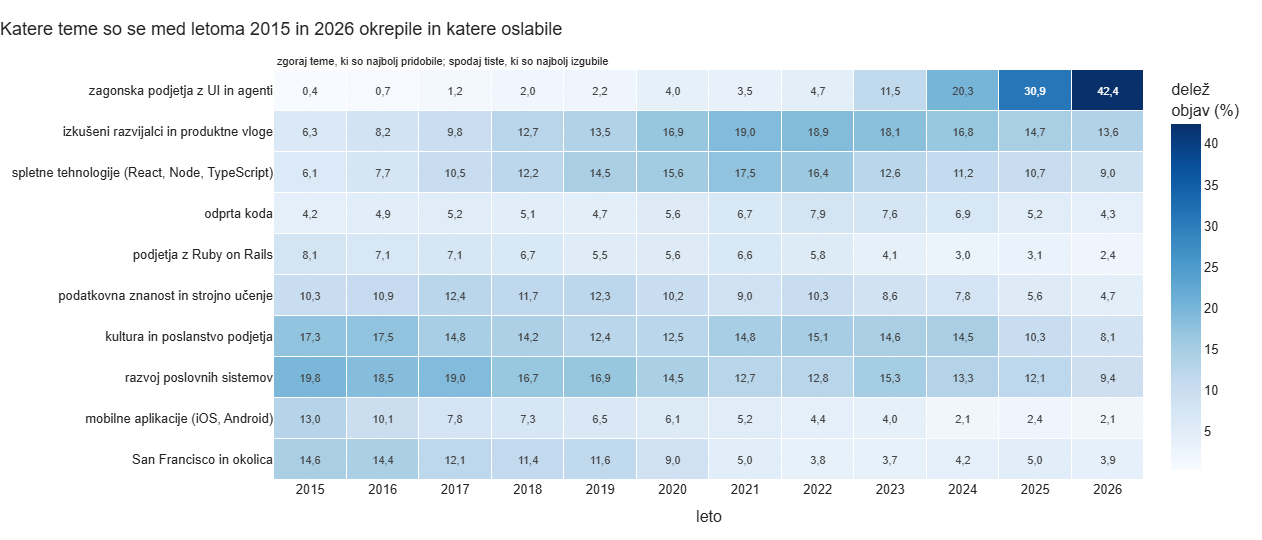

**Kaj vidimo?** Vsaka vrstica je ena tema, vsak stolpec eno leto. Številka v polju je povprečen delež objav tistega leta v odstotkih; temnejše polje pomeni večji delež. Teme so razvrščene po spremembi: zgoraj tiste, ki so najbolj pridobile, spodaj tiste, ki so najbolj izgubile.

**Zakaj smo to naredili?** Mesečne številke precej nihajo. Letna povprečja dajo bolj miren pregled, katere teme so v zadnjih letih dobile prostor.

**Kaj to pomeni?** Primerjali smo prva leta (2015-2017) z zadnjimi (2024-2026). Najbolj je pridobila »zagonska podjetja z UI in agenti«: z 0,8 % na 31,2 % objav. Najbolj je izgubila »San Francisco in okolica«: z 13,7 % na 4,4 %.

**Česa ne vemo?** Hacker News je kotiček trga, kjer prevladujejo zagonska podjetja (startupi) iz ZDA, zato ne predstavlja vseh delodajalcev. Zadnje leto je lahko nepopolno (podatki ne pokrivajo vseh mesecev), zato je njegovo povprečje manj zanesljivo. Teme je določil algoritem, zato meje med njimi niso ostre.

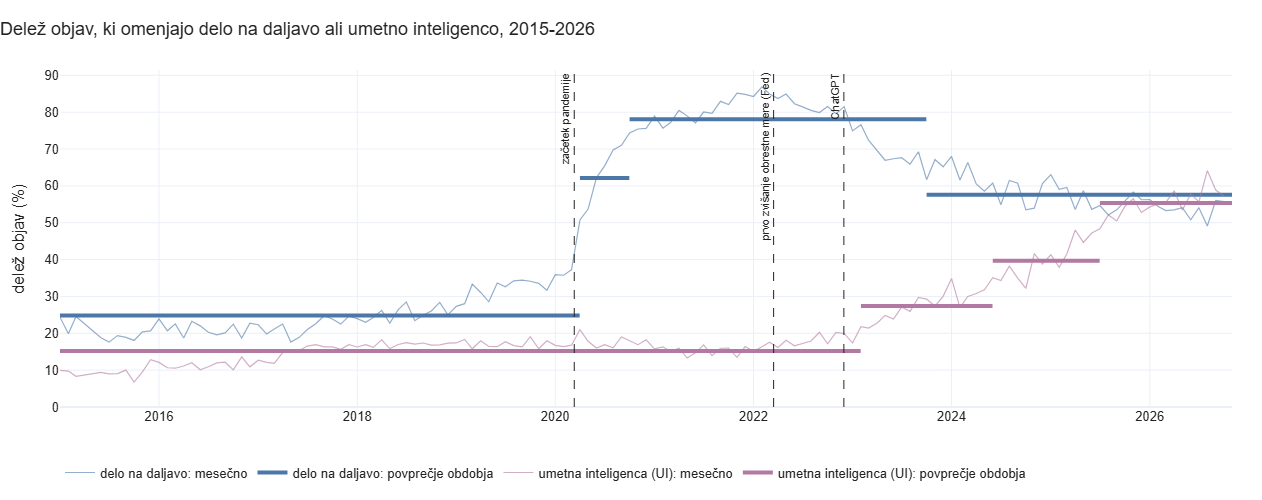

**Kaj vidimo?** Modra črta je delež objav, ki omenjajo delo na daljavo, vijolična delež objav, ki omenjajo umetno inteligenco ali strojno učenje. Debele vodoravne stopnice so povprečna raven med dvema premikoma: računalnik je poiskal mesece, ko se je raven najbolj spremenila (»premik skozi čas«). Črtkane črte označujejo začetek pandemije, prvo zvišanje obrestne mere in ChatGPT.

**Zakaj smo to naredili?** Želeli smo videti, kdaj točno sta se spremenili dve stvari, o katerih se največ govori: delo na daljavo in umetna inteligenca.

**Kaj to pomeni?** Omembe dela na daljavo so v prvih 12 mesecih zajemale 21 % objav, v zadnjih 12 mesecih 54 % (delež je narasel); vrh je bil 2/2022 s 87 %. Večji premiki ravni so se zgodili 4/2020, 10/2020, 10/2023. Omembe umetne inteligence so v prvih 12 mesecih zajemale 10 % objav, v zadnjih 12 mesecih 57 % (delež je narasel); vrh je bil 8/2026 s 64 %. Večji premiki ravni so se zgodili 2/2023, 6/2024, 7/2025.

**Česa ne vemo?** Hacker News je kotiček trga, kjer prevladujejo zagonska podjetja (startupi) iz ZDA, zato ne predstavlja vseh delodajalcev. Oznake temeljijo na iskanju ključnih besed: objava, ki napiše »no remote«, šteje kot omemba dela na daljavo. Premiki skozi čas so ocena (iskali smo največ tri), ne dokaz, da se je kaj zgodilo prav tisti mesec, in ne povedo, zakaj.

In [11]:
show_chapter(["4_teme_povrsina", "4_teme_mali_grafi", "4_teme_toplotna", "4_daljava_ui"], "4_",
             "*Poglavje o objavah delodajalcev bomo dodali, ko bodo podatki priključeni.*")

## 5. Kje v ZDA?

Še zemljevid: kako se je med letoma 2019 in 2024 spremenilo število delovnih mest v IT po ameriških metropolitanskih območjih. Pozor: IT je tu ozko opredeljen (računalniško programiranje, svetovanje in sorodne storitve), podatki za nekatera območja pa so zaradi zaupnosti skriti. Skrit podatek ni enak nič.

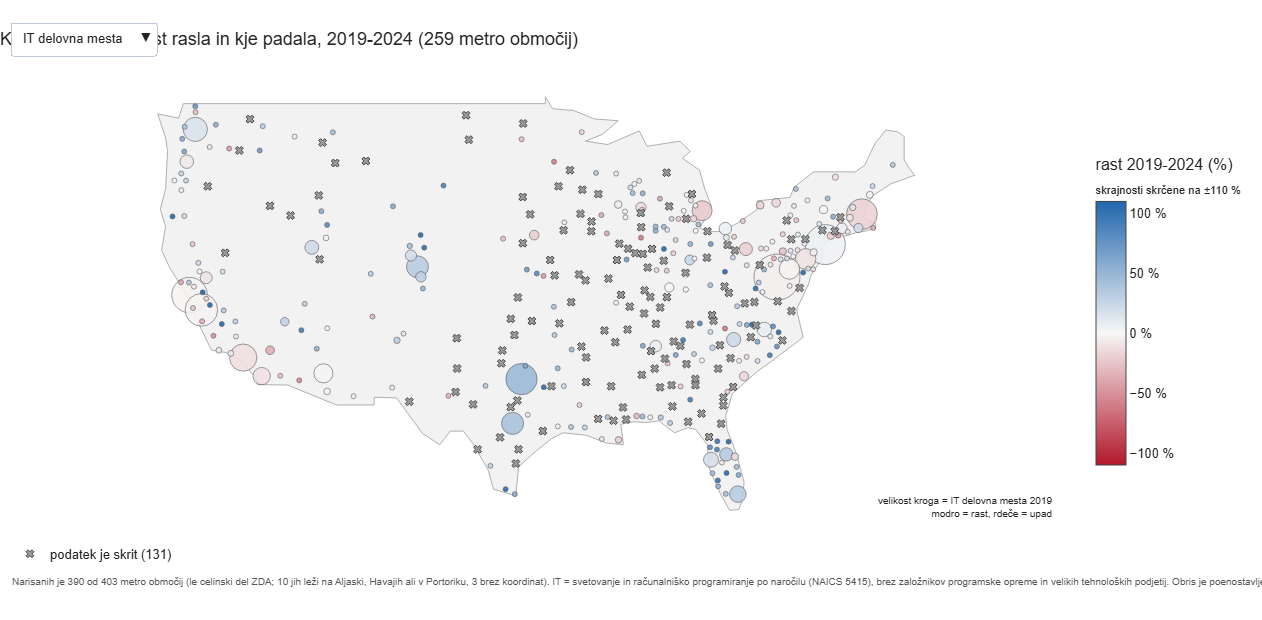

**Kaj vidimo?** Vsak krog je eno metro območje v ZDA (mesto z okolico). Velikost kroga pove, koliko ljudi je tam leta 2019 delalo v IT, barva pa, ali se je število do leta 2024 povečalo (modro) ali zmanjšalo (rdeče); bela pomeni skoraj brez spremembe. Sivi križci so območja, kjer je podatek skrit. Z menijem levo zgoraj preklopiš na rast števila IT podjetij; ko miško premakneš na krog, vidiš ime in številke.

**Zakaj smo to naredili?** Zanimalo nas je, ali se je IT delo po pandemiji preselilo: ali so velika tradicionalna središča izgubljala in manjša, cenejša mesta pridobivala.

**Kaj to pomeni?** Med 259 metro območji z uporabnim podatkom se je IT zaposlenost povečala v 62 % območij; pri tipičnem območju (mediana) je zrasla za 12,7 %. Med 25 največjimi je najbolj zrasel Dallas (+48 %), najslabše se je odrezal Detroit (−22 %). Število IT podjetij je pri tipičnem območju zraslo za 45 % (podatek imamo za 367 območij, ker se število podjetij ne skriva). Za 131 območij je podatek o zaposlenosti skrit ali nepopoln, med njimi Chicago, Atlanta, Minneapolis, Kansas City, Indianapolis.

**Česa ne vemo?** IT tukaj pomeni samo podjetja za svetovanje in programiranje po naročilu (NAICS 5415); založniki programske opreme in velika tehnološka podjetja niso všteti. Kjer je podatek skrit, to ni nič: urad ga ne objavi, da ne bi razkril posameznega podjetja. Primerjamo le dve leti, zato zemljevid ne pokaže, kaj se je dogajalo vmes. Rast pri majhnih območjih je lahko velika že zaradi enega podjetja. Zemljevid kaže, kje se je kaj spremenilo, ne pa zakaj.

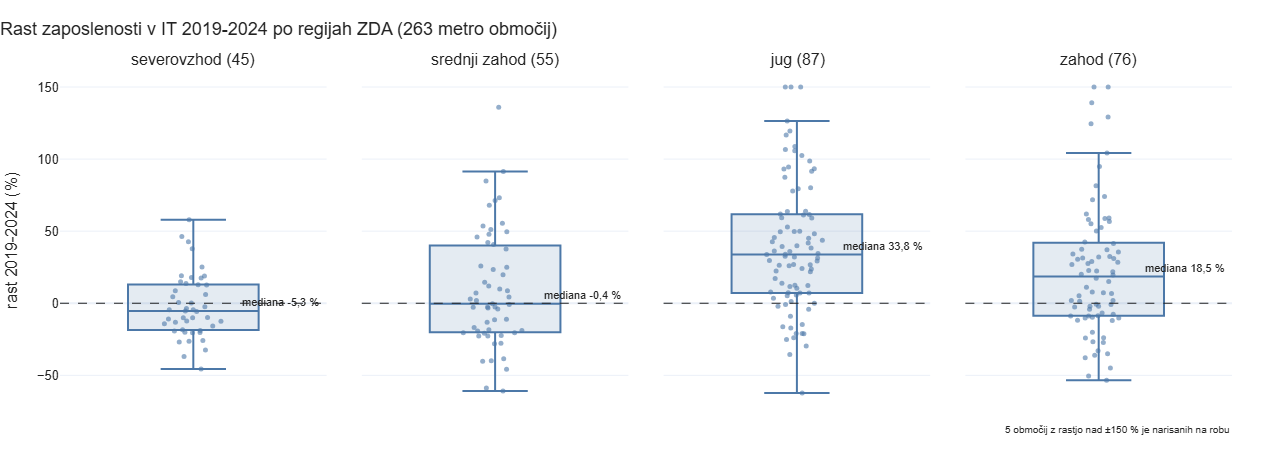

**Kaj vidimo?** Štirje grafi, po eden za vsako veliko regijo ZDA. Vsaka pika je eno metro območje, njena višina pa rast IT zaposlenosti med 2019 in 2024. Škatla zajame srednjo polovico območij, črta v njej in napis pa mediano (tipično območje). Ko miško premakneš na piko, vidiš ime.

**Zakaj smo to naredili?** Zemljevid kaže posamezna mesta, tukaj pa preverimo, ali je celoten jug ali zahod rasel hitreje kot severovzhod in srednji zahod.

**Kaj to pomeni?** Mediana rasti po regijah: severovzhod −5,3 % (45 območij); srednji zahod −0,4 % (55 območij); jug +33,8 % (87 območij); zahod +18,5 % (76 območij). Najvišja je na jugu, najnižja na severovzhodu; razlika med njima je 39,1 odstotne točke.

**Česa ne vemo?** IT tukaj pomeni samo podjetja za svetovanje in programiranje po naročilu (NAICS 5415); založniki programske opreme in velika tehnološka podjetja niso všteti. Kjer je podatek skrit, to ni nič: urad ga ne objavi, da ne bi razkril posameznega podjetja. Regijo določimo po prvi zvezni državi v imenu območja, kar pri območjih čez mejo držav ni povsem natančno. Vsako območje šteje enako, ne glede na velikost.

In [12]:
show_chapter(["5_zemljevid", "5_regije"], "5_", "*Zemljevid bomo dodali, ko bodo podatki priključeni.*")

## 6. Kaj naredi borza?

Za konec še borza: ali vlagatelji objavo odpuščanj nagradijo ali kaznujejo? Pogledali smo gibanje cene delnice okoli objav, ko odštejemo gibanje celotne borze.

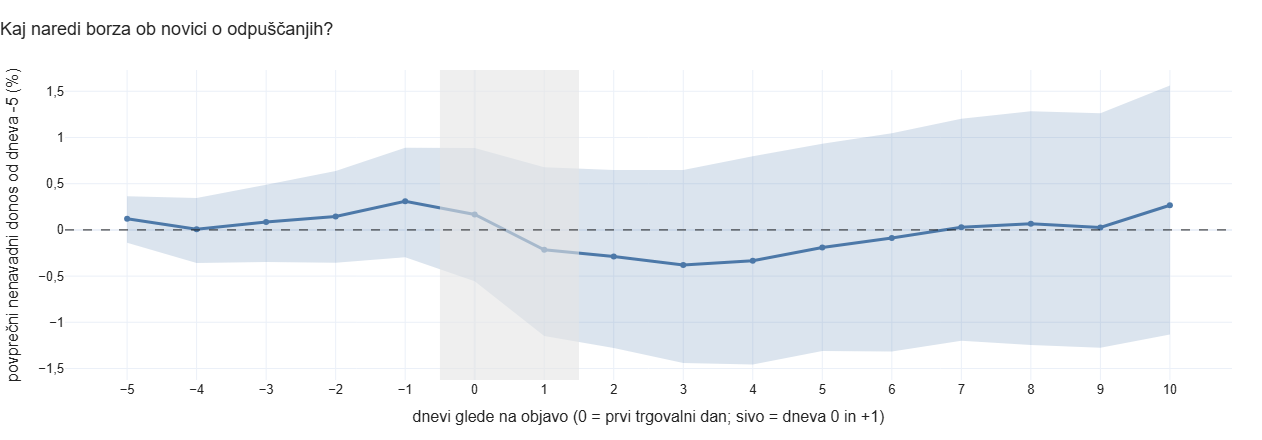

**Kaj vidimo?** Graf kaže, kako se je cena delnice v povprečju gibala v dneh okoli objave odpuščanj, ko od njenega gibanja odštejemo gibanje celotne borze (temu rečemo nenavadni donos). Dan 0 je prvi trgovalni dan po objavi; sivo območje označuje dneva 0 in +1, ko borza novico prebavi. Črta je povprečje preko 611 objav, modro območje je 95-odstotna negotovost. Ko miško premakneš na točko, vidiš vrednost.

**Zakaj smo to naredili?** Zanima nas, ali vlagatelji objavo odpuščanj nagradijo ali kaznujejo, torej ali je za borzo novica dobra ali slaba.

**Kaj to pomeni?** V dneh 0 in +1 se je cena v povprečju znižala za 0,6 % (negotovost od -1,3 % do 0,1 %). Ker negotovost zajema ničlo, ne moremo trditi, da je sprememba več kot naključje. V dneh pred objavo ni opaznega premika, kar je dober znak: novica očitno ni pricurljala vnaprej.

**Česa ne vemo?** Podjetja odpuščanja pogosto objavijo skupaj z rezultati poslovanja ali opozorili vlagateljem, zato učinka odpuščanj ne moremo ločiti od druge novice istega dne. Datum na seznamu je lahko dan prepozen. Podjetja, ki so kasneje izginila z borze, v podatkih manjkajo. Gre za povprečje: posamezne objave se zelo razlikujejo. Preizkus na naključnih dnevih kaže, da naš test v 9 % primerov zazna učinek, ki ga ni (pričakovanih je 5 %). Intervali so zato nekoliko preozki, kar pri rezultatu, ki že zajema ničlo, sklepa ne spremeni.

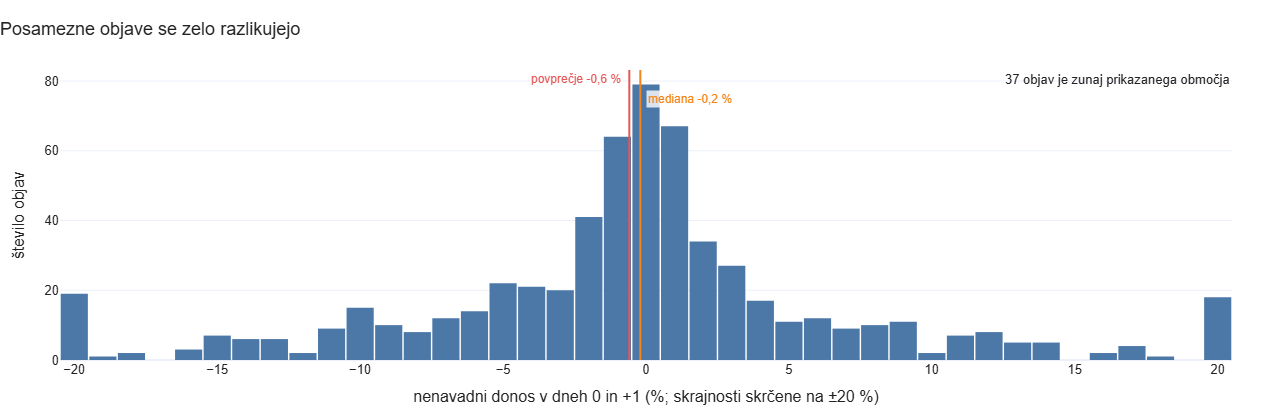

**Kaj vidimo?** Vsak stolpec šteje, koliko objav je imelo določen nenavadni donos v dneh 0 in +1 (v odstotkih). Rdeča črta je povprečje, oranžna mediana (sredinska vrednost, polovica objav je pod njo, polovica nad njo). Skrajne vrednosti smo skrčili na ±20 %, da je graf berljiv.

**Zakaj smo to naredili?** Povprečje lahko skriva, kako različne so posamezne objave, zato pogledamo vse.

**Kaj to pomeni?** Pri polovici objav se je cena premaknila za manj kot 3,0 %, pri devetih od desetih za manj kot 14,0 %. Navzgor jo je potisnilo 48 % objav, navzdol 52 %. Mediana je -0,2 %, povprečje -0,6 %.

**Česa ne vemo?** Razpršenost je tudi posledica običajnega nihanja posameznih delnic, ne le novice o odpuščanjih. Z nekaj sto objavami lahko govorimo o skupini podjetij, ne o posameznem podjetju.

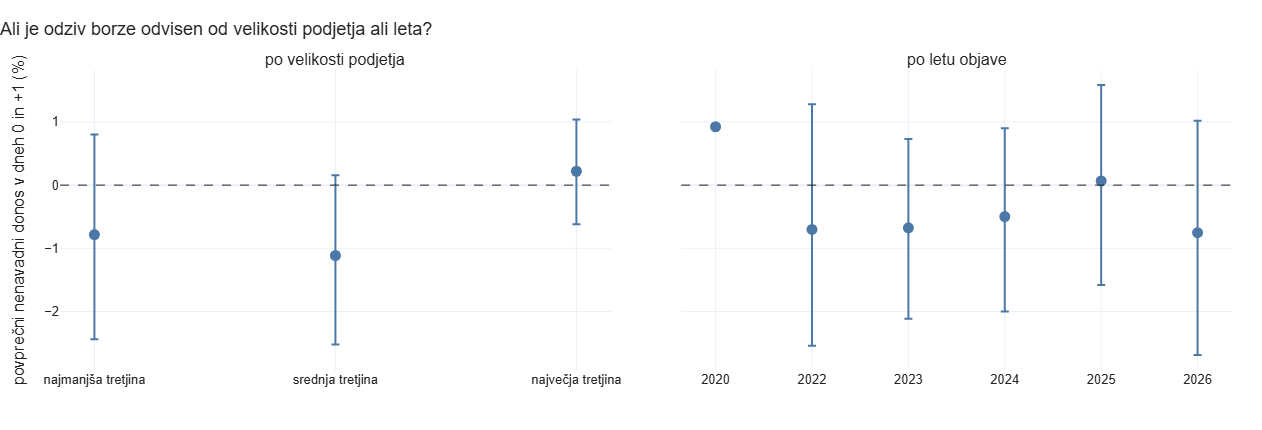

**Kaj vidimo?** Levo so podjetja razdeljena v tretjine po velikosti, desno po letu objave. Pika je povprečni nenavadni donos v dneh 0 in +1, črte kažejo 95-odstotno negotovost. Če črta prečka ničlo, ne moremo reči, da se je cena sploh premaknila. Skupin z manj kot 10 objavami ne kažemo.

**Zakaj smo to naredili?** Zanima nas, ali je odziv borze drugačen pri majhnih in velikih podjetjih ali v različnih letih, na primer med največjim valom odpuščanj leta 2022 in pozneje.

**Kaj to pomeni?** Po velikosti: najmanjša tretjina: -0,8 % (od -2,4 do 0,8 %); srednja tretjina: -1,1 % (od -2,5 do 0,2 %); največja tretjina: 0,2 % (od -0,6 do 1,0 %). Razlika med najmanjšimi in največjimi podjetji je -1,0 odstotne točke (negotovost od -2,8 do 1,1), kar ni statistično zanesljivo. Po letih pri nobenem letu negotovost ne izključuje ničle, zato jasnega vzorca ni.

**Česa ne vemo?** V posamezni skupini je od nekaj deset do dvesto objav, zato so razlike negotove. Hkrati primerjamo več skupin, zato je lahko katera 'opazna' razlika tudi naključna. Velikost je merjena z vrednostjo sredstev pred objavo, ne z vrednostjo podjetja na borzi.

In [13]:
show_chapter(["6_pot", "6_porazdelitev", "6_skupine"], "6_",
             "*Ta del bo na voljo, ko bodo prenesene cene delnic (python collect.py --sources prices).*")

## Povzetek

In [14]:
povzetek = tx.build_summary(story)
display(Markdown("### Kaj smo se naučili\n\n" + "\n\n".join(f"- {x}" for x in povzetek["zakljucki"])))
display(Markdown("### Česa ne vemo\n\n" + "\n\n".join(f"- {x}" for x in povzetek["odprto"])))

### Kaj smo se naučili

- **Kdaj:** napovedi odpuščanj so se močno povečale spomladi 2022. Pred prvim zvišanjem obrestne mere jih je bilo povprečno 1,0 na teden, po njem 15,4. Ob izidu ChatGPT se je število skoraj nespremenjeno (21,3 pred, 21,6 po).

- **Zakaj:** število napovedi sledi obrestnim meram in borzi, števila odpuščenih ljudi in uradne statistike pa isti vzorec ne ujame. Seznam torej bolj kaže, kdaj so podjetja objavljala odpuščanja, kot koliko ljudi je izgubilo delo.

- **Katera podjetja (rast):** podjetja, ki so v letih 2019 do 2021 najhitreje rasla, so pozneje pogosteje napovedala odpuščanja (23 % proti 5 % pri najpočasnejših), vendar ne zato, ker bi jim stroški rasli hitreje od prihodkov.

- **Katera podjetja (velikost):** največ pove velikost podjetja. Samo z njo dosežemo 0,28 (naključje 0,05), model z računovodskimi kazalniki 0,22, brez velikosti pa 0,08.

- **Kaj iščejo delodajalci:** delež objav na Hacker Newsu, ki omenjajo delo na daljavo, je bil leta 2019 32 %, na vrhuncu (12-mesečno povprečje do 8/2022) 84 %, v zadnjih 12 mesecih pa 54 %; delež objav z umetno inteligenco je z 10 % v prvih 12 mesecih narasel na 57 % v zadnjih 12 mesecih. To je vzorec iz kotička trga s prevlado zagonskih podjetij, ne slika vseh delodajalcev.

- **Kje:** med 259 ameriškimi metro območji z uporabnim podatkom se je IT zaposlenost (svetovanje in programiranje po naročilu) med letoma 2019 in 2024 povečala v 62 % območij; pri tipičnem območju (mediana) je zrasla za 12,7 %. Za 131 območij je podatek skrit ali nepopoln, kar ni enako nič.

- **Borza:** ob objavi odpuščanj se cena delnice v povprečju znižala za 0,6 % (negotovost od -1,3 do 0,1 %), kar ni jasno več kot naključje.

### Česa ne vemo

- Seznam odpuščanj beleži napovedi predvsem znanih podjetij, ne vseh odpuščanj; tudi uradna statistika kaže manj dramatično sliko kot seznam.

- Vse povezave so povezave v času, ne dokaz vzroka: imamo en cikel obrestnih mer in nekaj sto podjetij.

- Nimamo števila zaposlenih in ne vemo, ali je bil razlog za odpuščanja umetna inteligenca.

- Podjetja, ki so kasneje izginila z borze, v podatkih o cenah manjkajo.

## Viri

- Layoffs.fyi: seznam napovedanih odpuščanj v tehnološkem sektorju.
- US Securities and Exchange Commission (EDGAR): javni računovodski podatki podjetij.
- Federal Reserve Bank of St. Louis (FRED): obrestna mera Fed in indeks NASDAQ Composite.
- US Bureau of Labor Statistics: zaposlenost po panogah (QCEW), statistika odpuščanj (JOLTS).
- Hacker News: mesečne objave "Ask HN: Who is hiring?".
- US Census Bureau: podatki o metropolitanskih območjih.
- Yahoo Finance (prek paketa yfinance): dnevne cene delnic, samo za raziskovalno rabo.